In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv(r"/content/Adult Census Income.csv",na_values='?')

In [4]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [5]:
df['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [6]:
df['workclass'].unique()

array([nan, 'Private', 'State-gov', 'Federal-gov', 'Self-emp-not-inc',
       'Self-emp-inc', 'Local-gov', 'Without-pay', 'Never-worked'],
      dtype=object)

In [7]:
df.shape

(32561, 15)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [9]:
df.isna().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [10]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [11]:
df.duplicated().sum()


np.int64(24)

In [12]:
df=df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

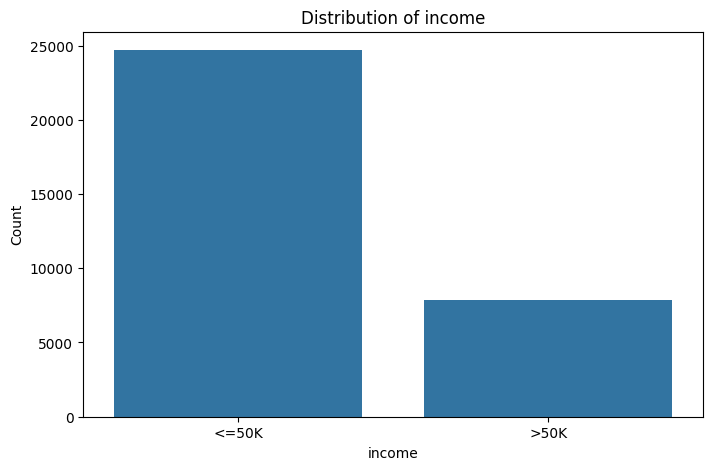

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='income')

plt.title('Distribution of income')
plt.xlabel('income')
plt.ylabel('Count')
plt.show()

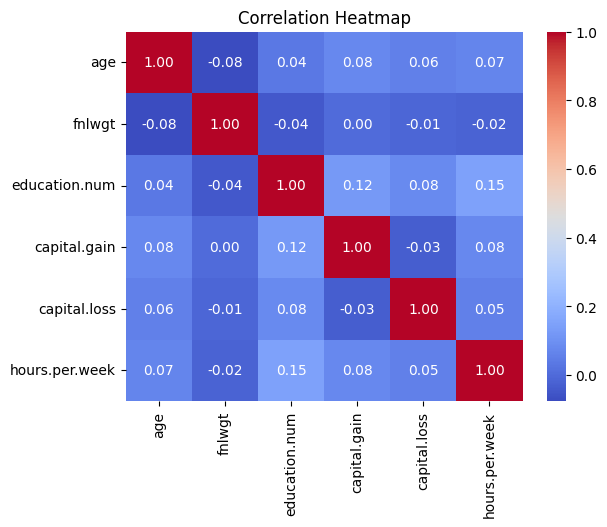

In [14]:
nums = df.select_dtypes(include='number')

sns.heatmap(
    nums.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

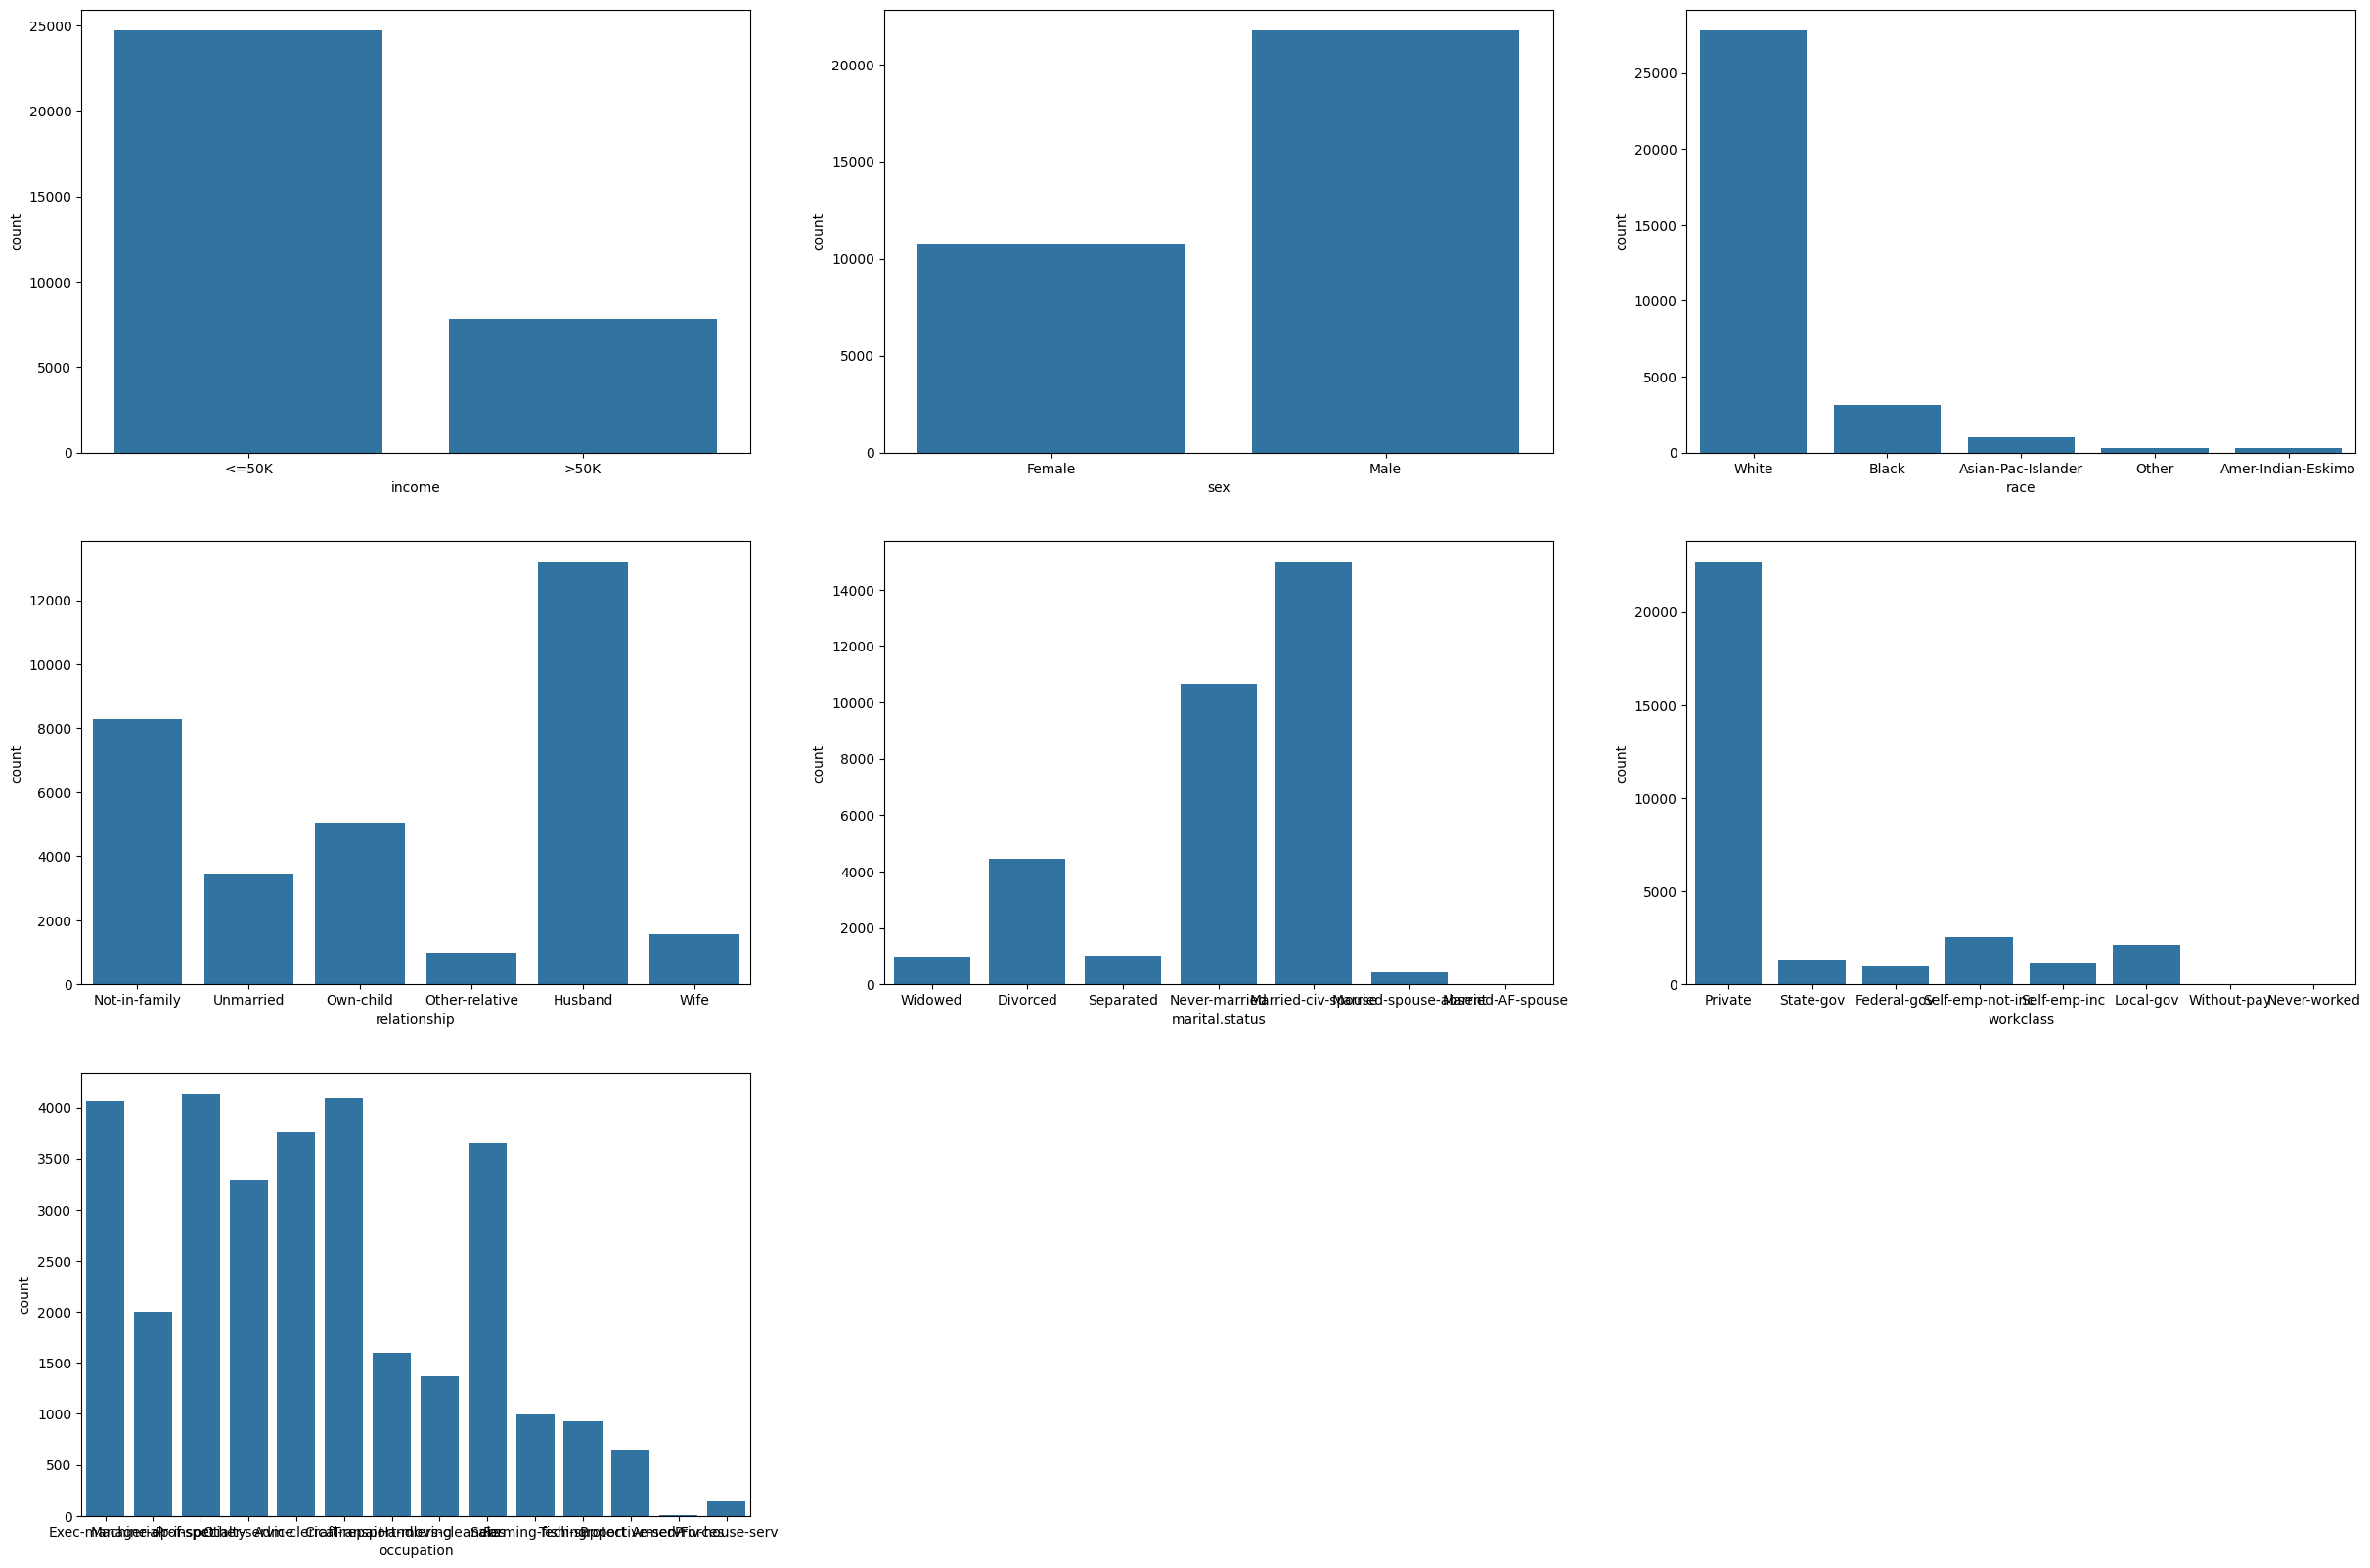

In [15]:
cols = list(df.nunique().sort_values().index[:7])

plt.figure(figsize=(30,20))
for n , col in enumerate(cols) :
    plt.subplot(3,3,n+1)
    sns.countplot(data=df,x=col)

In [16]:
st=df.select_dtypes(include='O')
for i in st:
    print(i,df[i].nunique())
    print('*'*150)

workclass 8
******************************************************************************************************************************************************
education 16
******************************************************************************************************************************************************
marital.status 7
******************************************************************************************************************************************************
occupation 14
******************************************************************************************************************************************************
relationship 6
******************************************************************************************************************************************************
race 5
******************************************************************************************************************************************************
sex 2
**********

In [17]:
x=df.drop(columns=['income'])
y=df['income']

In [18]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=42,shuffle= True,stratify=y)

In [19]:
from sklearn.impute import SimpleImputer
impute = SimpleImputer(missing_values=np.nan,strategy='most_frequent')
x_train[['workclass']]=impute.fit_transform(x_train[['workclass']])
x_test[['workclass']]=impute.transform(x_test[['workclass']])

In [20]:
x_train[['native.country']]=impute.fit_transform(x_train[['native.country']])
x_test[['native.country']]=impute.transform(x_test[['native.country']])



In [21]:
x_train[['occupation']]=impute.fit_transform(x_train[['occupation']])
x_test[['occupation']]=impute.transform(x_test[['occupation']])

In [22]:
from sklearn.preprocessing import LabelEncoder
st = df.select_dtypes(include='O').columns.tolist()
st.remove('income')
for i in st:
    le = LabelEncoder()
    x_train[i] = le.fit_transform(x_train[i])
    x_test[i] = x_test[i].map(
        lambda x: le.transform([x])[0] if x in le.classes_ else -1
    )

In [23]:
from sklearn.preprocessing import StandardScaler
scalar=StandardScaler()
for i in nums:
     x_train[i]=scalar.fit_transform(x_train[[i]])
     x_test[i]=scalar.transform(x_test[[i]])

In [24]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (39516, 14)  y_train_smote =  (39516,)


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,f1_score,recall_score,precision_score
results = []

model = LogisticRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

results.append({

    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision':precision_score(y_test, y_pred, pos_label='>50K'),
    'Recall': recall_score(y_test, y_pred,pos_label='>50K'),
    'F1-Score': f1_score(y_test, y_pred,pos_label='>50K')

})

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)

model.fit(x_train, y_train)
y_pred = model.predict(x_test)
results.append({

    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision':precision_score(y_test, y_pred, pos_label='>50K'),
    'Recall': recall_score(y_test, y_pred,pos_label='>50K'),
    'F1-Score': f1_score(y_test, y_pred,pos_label='>50K'),

})

In [29]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

model.fit(x_train, y_train)
y_pred = model.predict(x_test)
results.append({

    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision':precision_score(y_test, y_pred, pos_label='>50K'),
    'Recall': recall_score(y_test, y_pred,pos_label='>50K'),
    'F1-Score': f1_score(y_test, y_pred,pos_label='>50K')

})

In [30]:
results

[{'Accuracy': 0.8219114935464045,
  'Precision': 0.7080366225839267,
  'Recall': 0.44387755102040816,
  'F1-Score': 0.5456683653469228},
 {'Accuracy': 0.8191456668715427,
  'Precision': 0.647993943981832,
  'Recall': 0.5459183673469388,
  'F1-Score': 0.5925925925925926},
 {'Accuracy': 0.8062384757221881,
  'Precision': 0.6955414012738853,
  'Recall': 0.3482142857142857,
  'F1-Score': 0.46408839779005523}]

In [37]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [32]:
pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 31.2 MB/s  0:00:03


In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [35]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

In [34]:
from tqdm import tqdm

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4656  284]
 [ 866  702]]


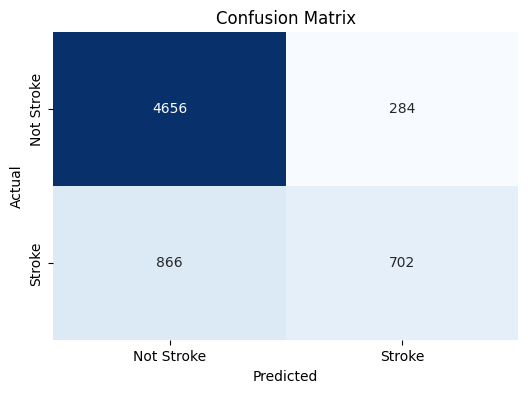


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.94      0.89      4940
      Stroke       0.71      0.45      0.55      1568

    accuracy                           0.82      6508
   macro avg       0.78      0.70      0.72      6508
weighted avg       0.81      0.82      0.81      6508

ROC-AUC: 0.8494278278112863


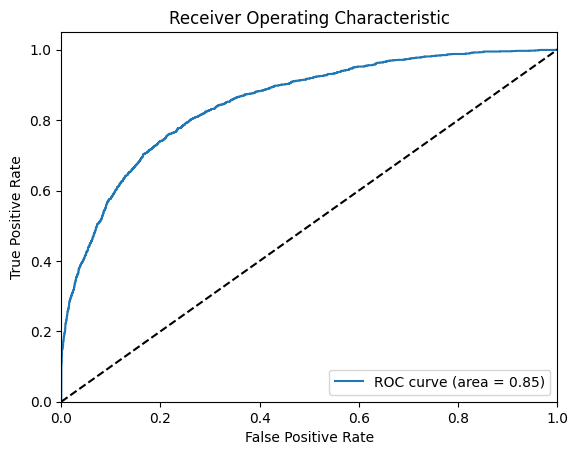

PR AUC: 0.6885118622099894


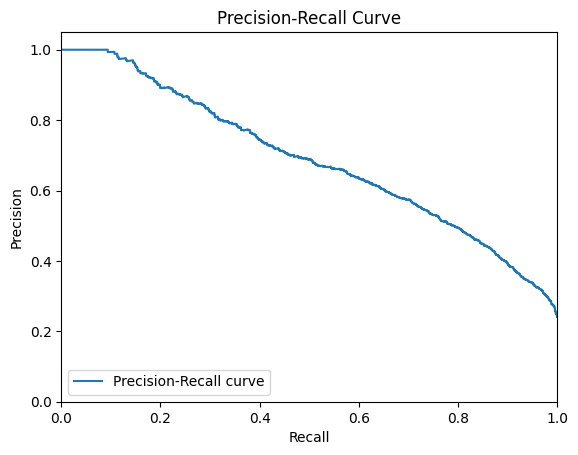

  8%|▊         | 1/13 [00:00<00:11,  1.06it/s]


Confusion Matrix:
 [[4475  465]
 [ 712  856]]


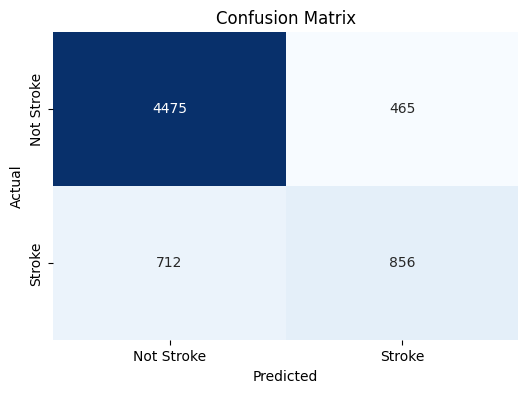


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.86      0.91      0.88      4940
      Stroke       0.65      0.55      0.59      1568

    accuracy                           0.82      6508
   macro avg       0.76      0.73      0.74      6508
weighted avg       0.81      0.82      0.81      6508

ROC-AUC: 0.8332966258365695


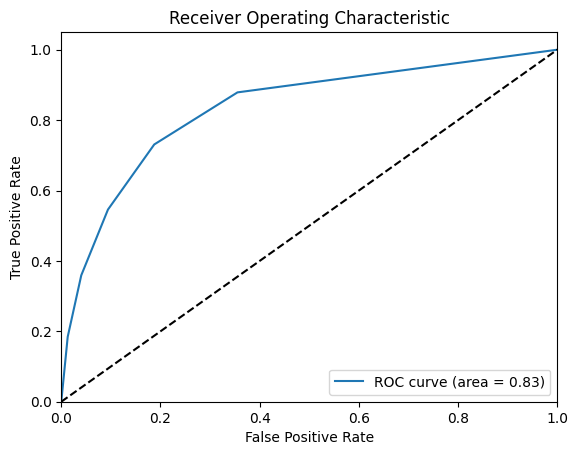

PR AUC: 0.5976555777138444


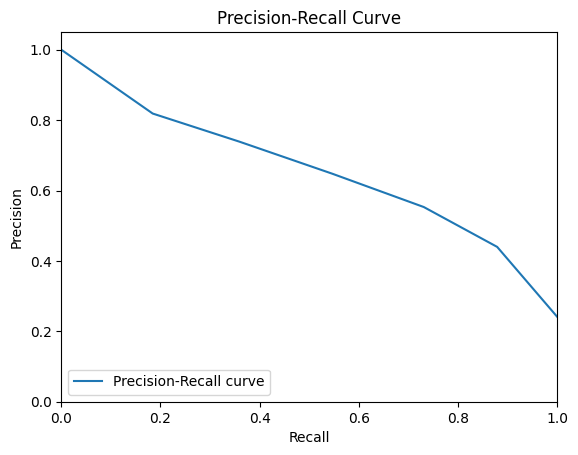

 15%|█▌        | 2/13 [00:11<01:11,  6.46s/it]


Confusion Matrix:
 [[4863   77]
 [1174  394]]


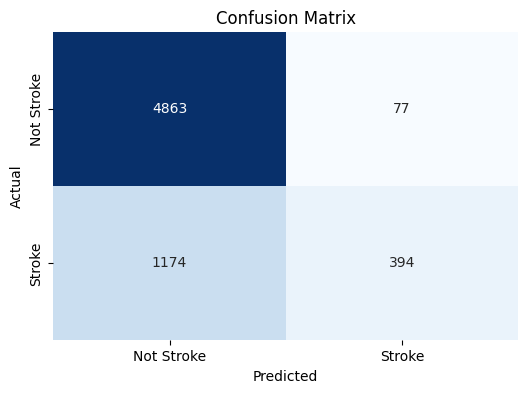


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.98      0.89      4940
      Stroke       0.84      0.25      0.39      1568

    accuracy                           0.81      6508
   macro avg       0.82      0.62      0.64      6508
weighted avg       0.81      0.81      0.77      6508

ROC-AUC: 0.8517920401966453


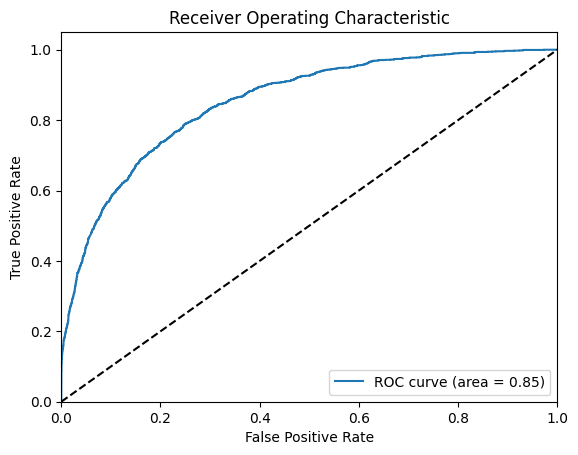

PR AUC: 0.6859147914345005


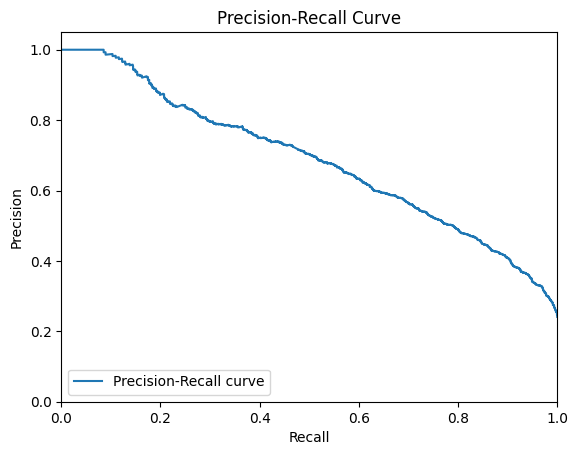

 23%|██▎       | 3/13 [04:17<19:21, 116.13s/it]


Confusion Matrix:
 [[4284  656]
 [ 635  933]]


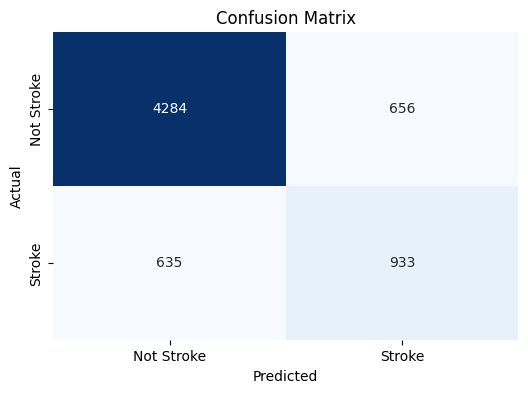


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.87      0.87      4940
      Stroke       0.59      0.60      0.59      1568

    accuracy                           0.80      6508
   macro avg       0.73      0.73      0.73      6508
weighted avg       0.80      0.80      0.80      6508

ROC-AUC: 0.7311159939684376


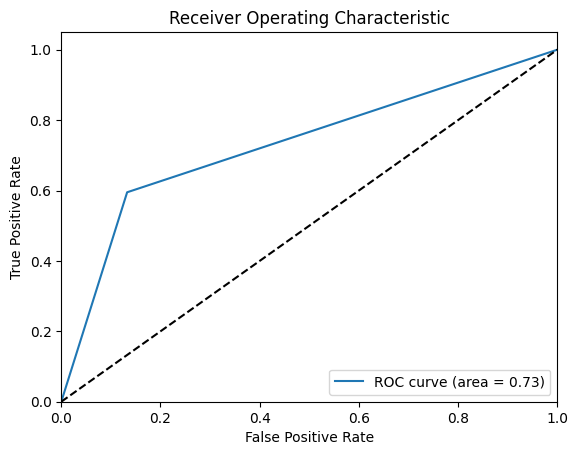

PR AUC: 0.446948430903536


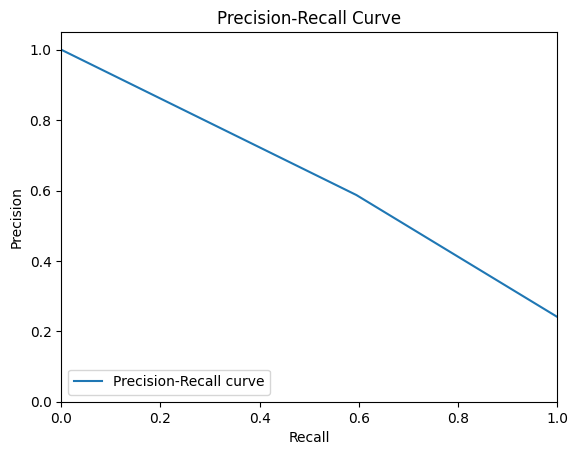

 31%|███       | 4/13 [04:18<10:35, 70.60s/it] 


Confusion Matrix:
 [[4701  239]
 [1022  546]]


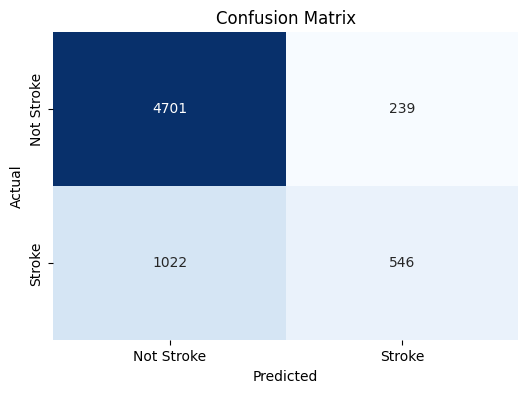


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.82      0.95      0.88      4940
      Stroke       0.70      0.35      0.46      1568

    accuracy                           0.81      6508
   macro avg       0.76      0.65      0.67      6508
weighted avg       0.79      0.81      0.78      6508

ROC-AUC: 0.8512210299099396


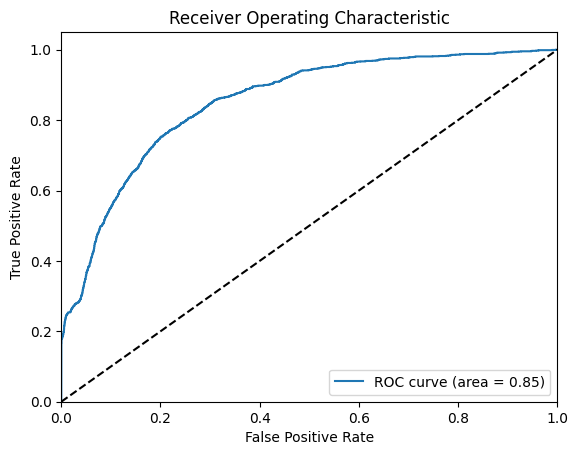

PR AUC: 0.6769492059543915


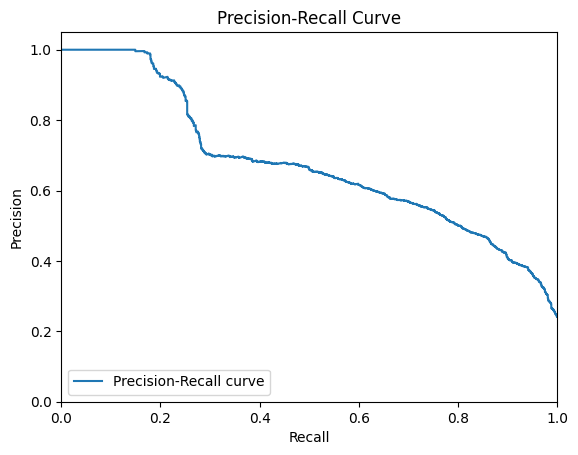

 38%|███▊      | 5/13 [04:19<06:02, 45.31s/it]


Confusion Matrix:
 [[4595  345]
 [ 609  959]]


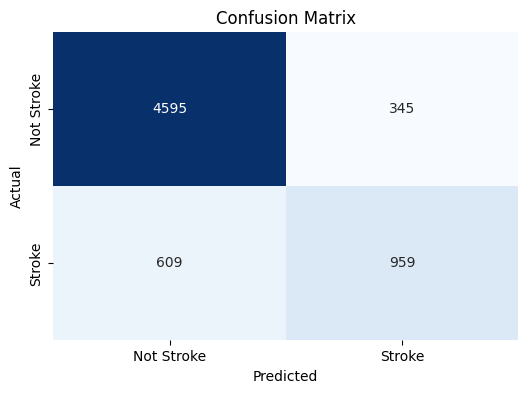


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.93      0.91      4940
      Stroke       0.74      0.61      0.67      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.77      0.79      6508
weighted avg       0.85      0.85      0.85      6508

ROC-AUC: 0.8978113639180367


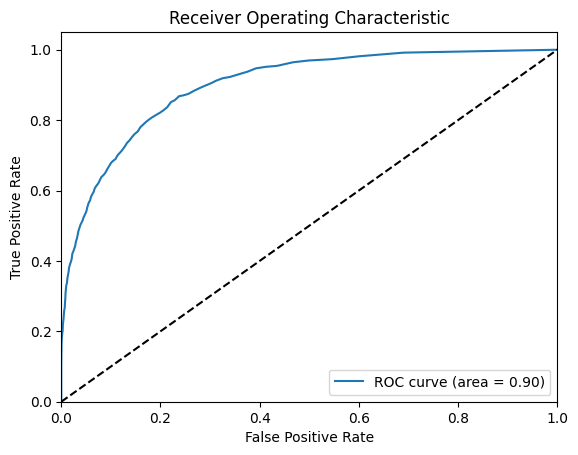

PR AUC: 0.7679877998488581


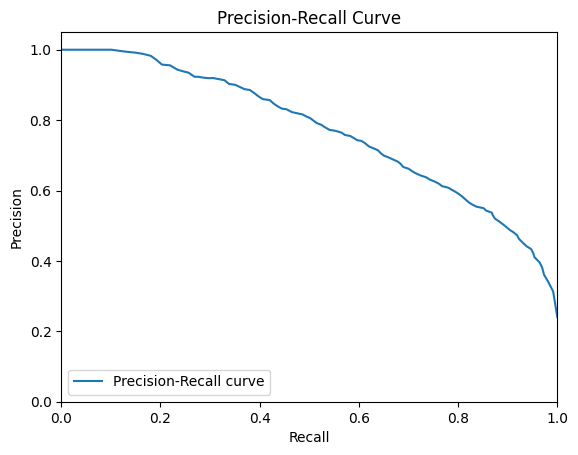

 46%|████▌     | 6/13 [04:23<03:40, 31.43s/it]


Confusion Matrix:
 [[4522  418]
 [ 635  933]]


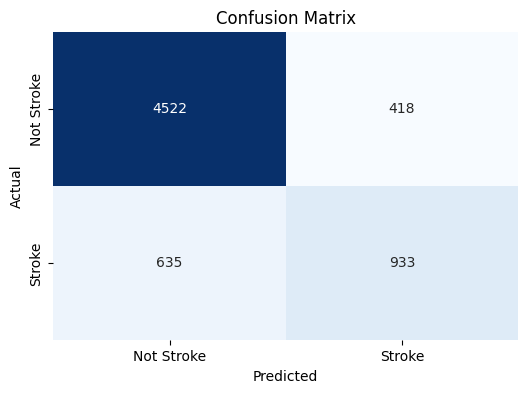


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.92      0.90      4940
      Stroke       0.69      0.60      0.64      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.76      0.77      6508
weighted avg       0.83      0.84      0.83      6508

ROC-AUC: 0.8802042236428984


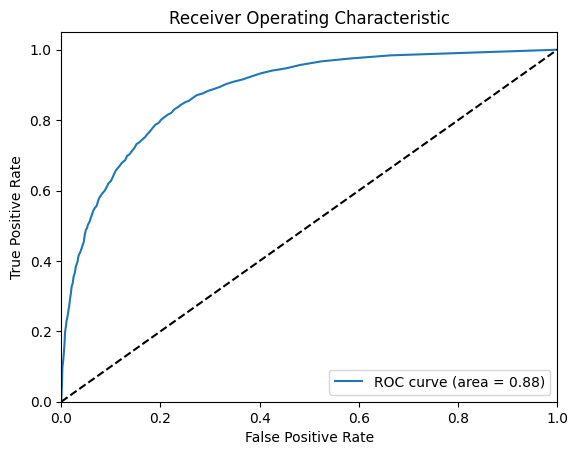

PR AUC: 0.7101979943750134


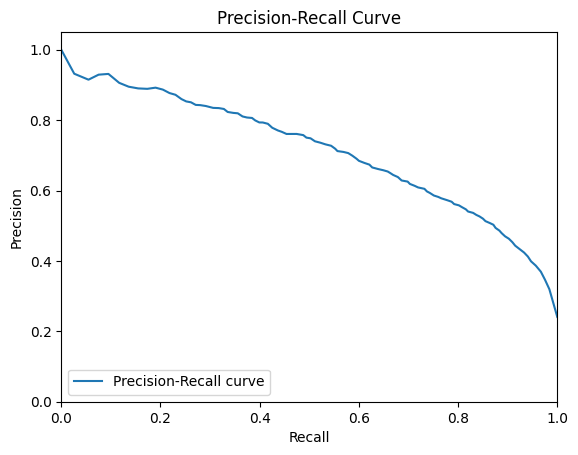

 54%|█████▍    | 7/13 [04:27<02:15, 22.51s/it]


Confusion Matrix:
 [[4701  239]
 [ 753  815]]


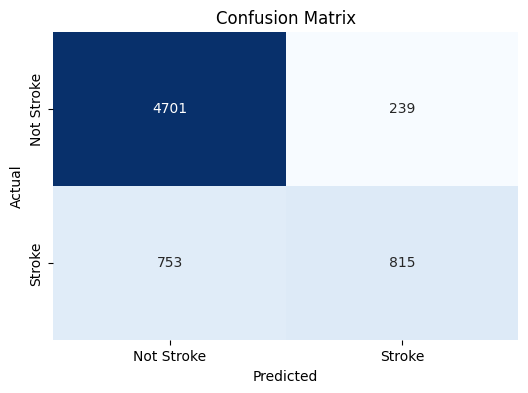


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.86      0.95      0.90      4940
      Stroke       0.77      0.52      0.62      1568

    accuracy                           0.85      6508
   macro avg       0.82      0.74      0.76      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8943702620218128


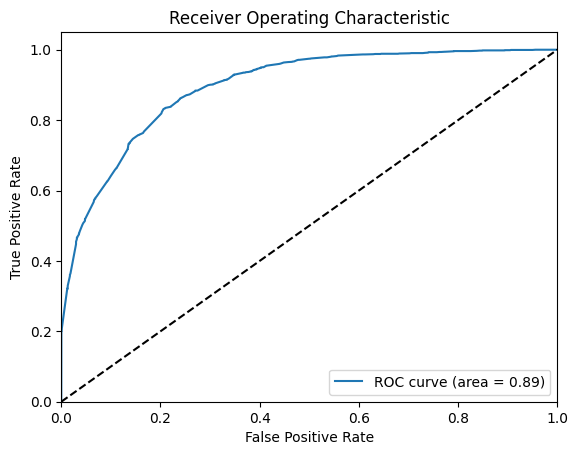

PR AUC: 0.7520206651620014


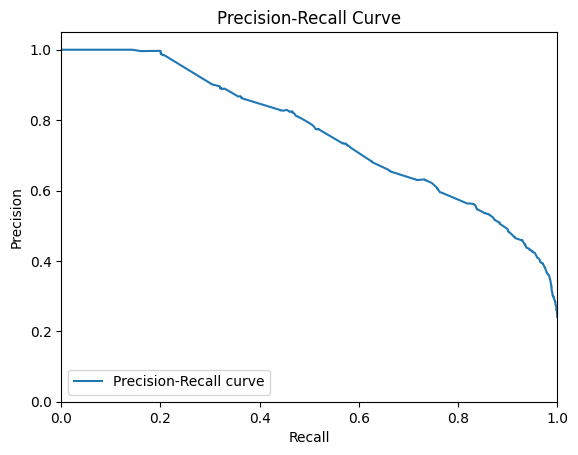

 62%|██████▏   | 8/13 [04:29<01:19, 15.97s/it]


Confusion Matrix:
 [[4681  259]
 [ 659  909]]


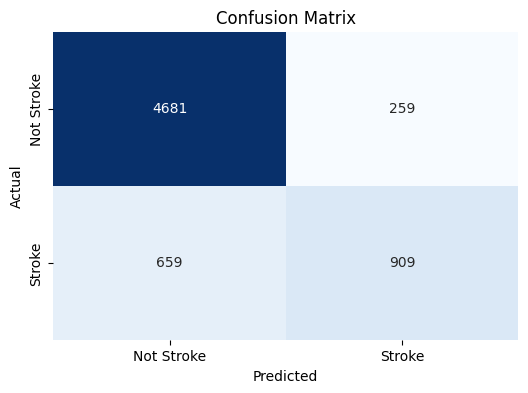


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.95      0.91      4940
      Stroke       0.78      0.58      0.66      1568

    accuracy                           0.86      6508
   macro avg       0.83      0.76      0.79      6508
weighted avg       0.85      0.86      0.85      6508

ROC-AUC: 0.9130966366809881


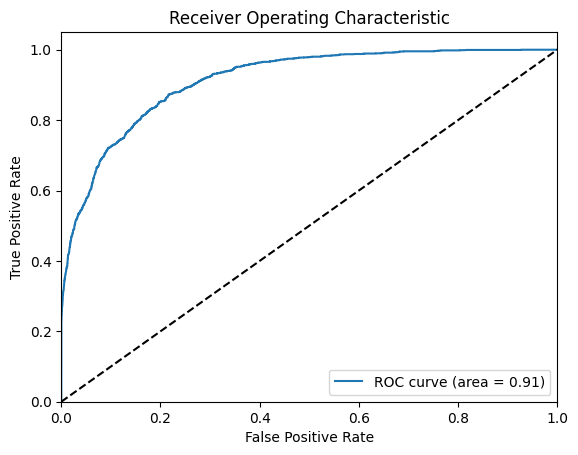

PR AUC: 0.8045104023297708


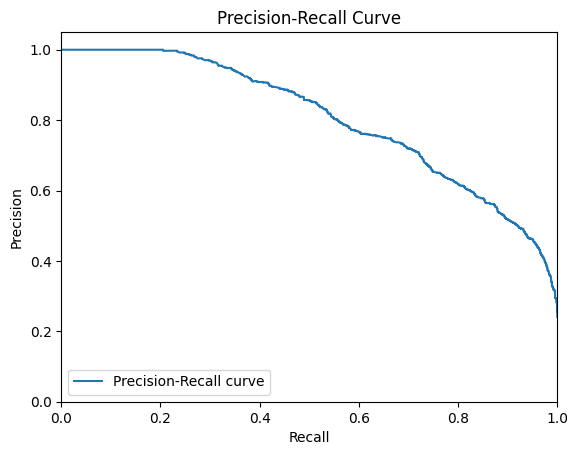

 69%|██████▉   | 9/13 [04:34<00:50, 12.57s/it]


Confusion Matrix:
 [[4643  297]
 [ 573  995]]


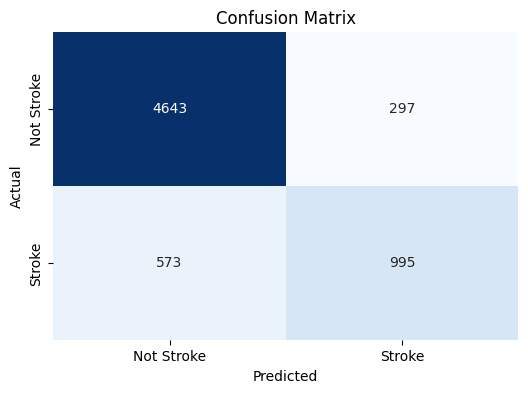


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.77      0.63      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.9194219666611585


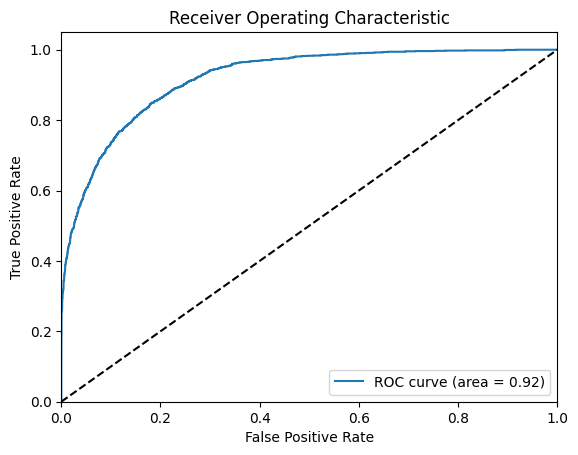

PR AUC: 0.8160399184109987


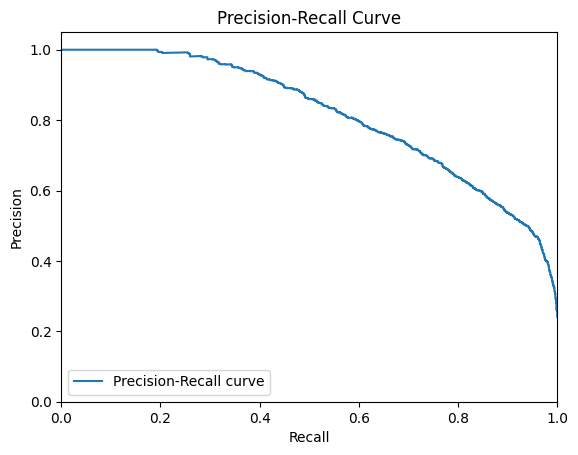

 77%|███████▋  | 10/13 [04:36<00:27,  9.22s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:56:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4621  319]
 [ 577  991]]


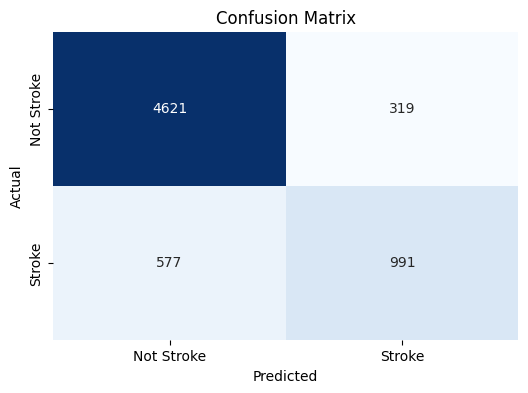


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.76      0.63      0.69      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.78      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.9188240389779393


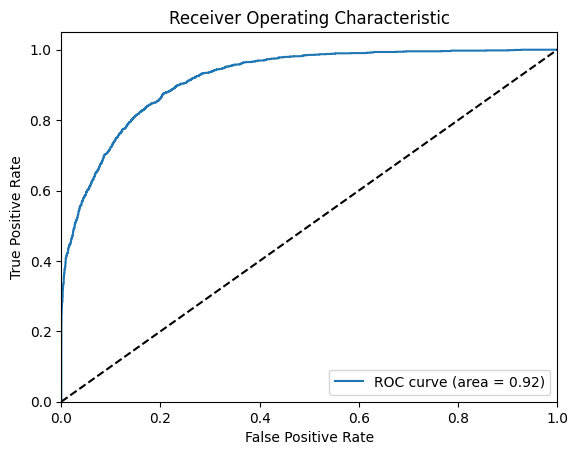

PR AUC: 0.8136606865928244


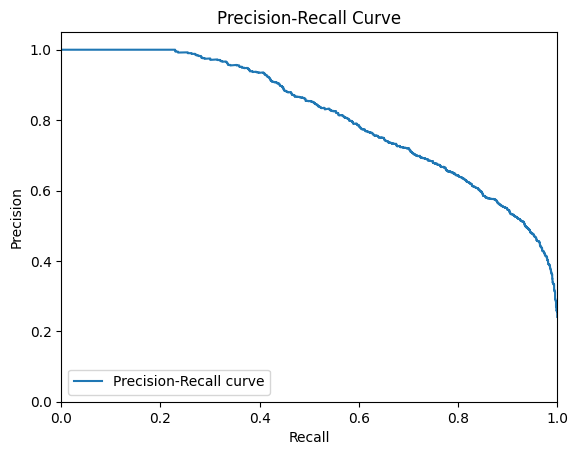

 85%|████████▍ | 11/13 [04:37<00:13,  6.71s/it]


Confusion Matrix:
 [[4650  290]
 [ 579  989]]


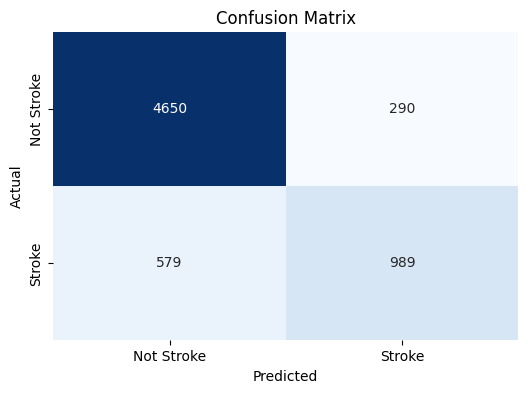


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.77      0.63      0.69      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.80      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.920158806184417


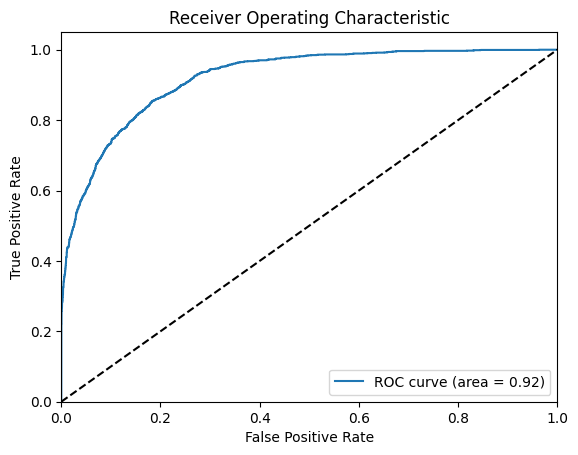

PR AUC: 0.8173690663722492


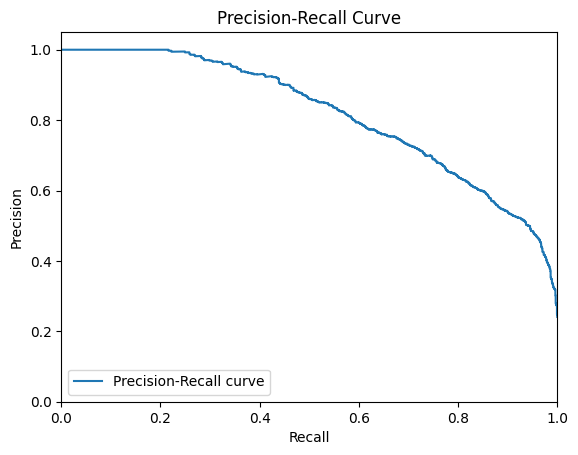

 92%|█████████▏| 12/13 [04:48<00:07,  7.92s/it]

[LightGBM] [Info] Number of positive: 6271, number of negative: 19758
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003978 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 689
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 14
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.240924 -> initscore=-1.147623
[LightGBM] [Info] Start training from score -1.147623

Confusion Matrix:
 [[4634  306]
 [ 562 1006]]


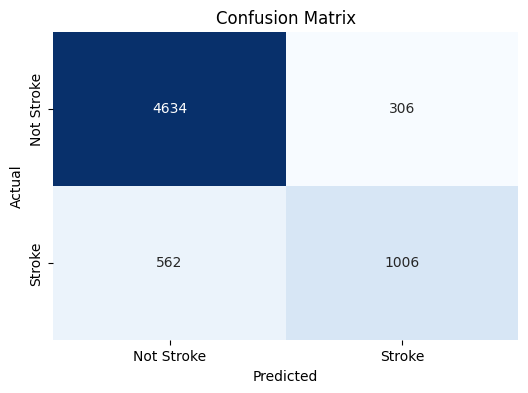


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.94      0.91      4940
      Stroke       0.77      0.64      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.920219225088821


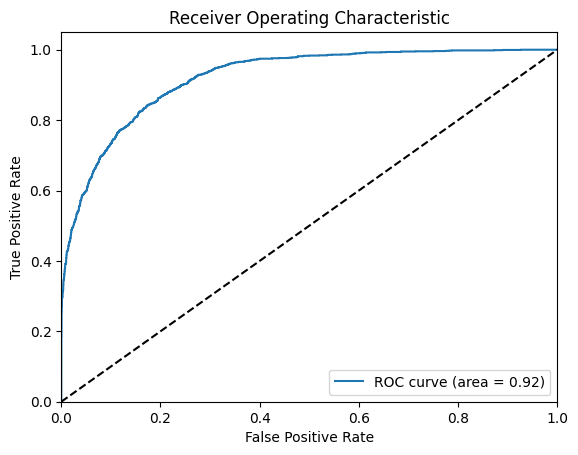

PR AUC: 0.8176815743054573


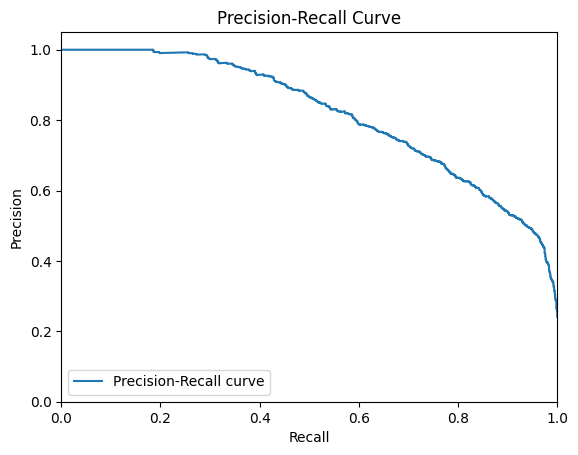

100%|██████████| 13/13 [04:49<00:00, 22.27s/it]


In [38]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred  = model.predict(x_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(x_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:58:52] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4781  159]
 [ 793  775]]


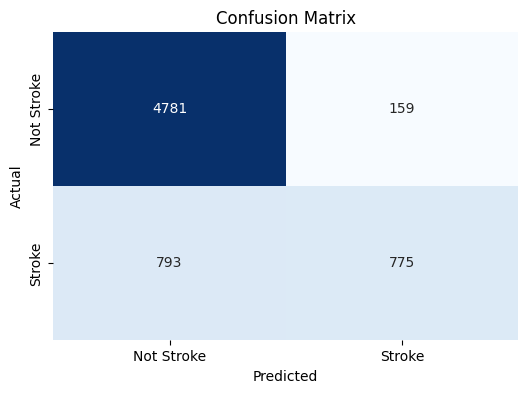


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.86      0.97      0.91      4940
      Stroke       0.83      0.49      0.62      1568

    accuracy                           0.85      6508
   macro avg       0.84      0.73      0.76      6508
weighted avg       0.85      0.85      0.84      6508

ROC-AUC: 0.9007990012806741


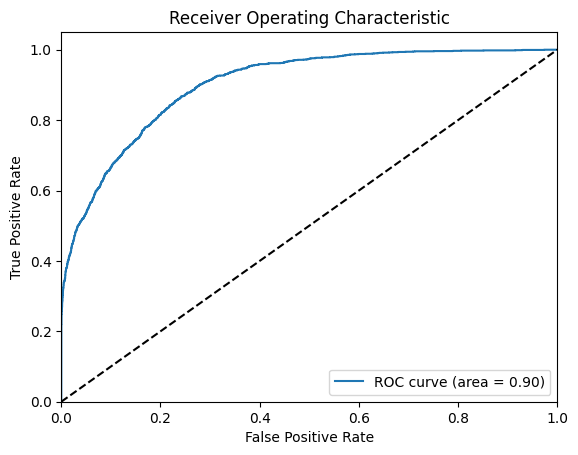

PR AUC: 0.7823997252389765


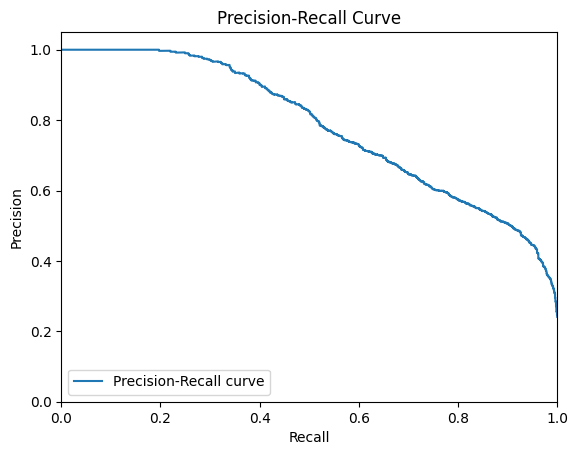

In [39]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(x_train, y_train)
voting_train_pred = voting_model.predict(x_train)
voting_test_pred = voting_model.predict(x_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:59:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4601  339]
 [ 562 1006]]


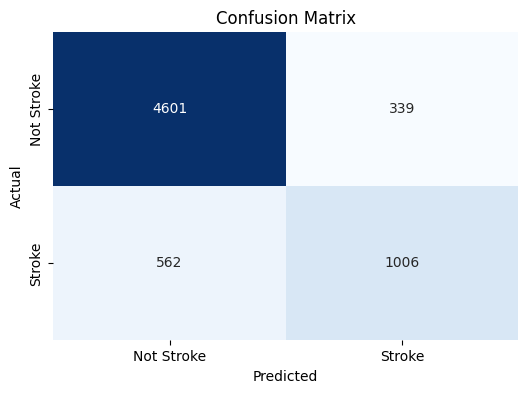


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.93      0.91      4940
      Stroke       0.75      0.64      0.69      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.79      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.9149622640047921


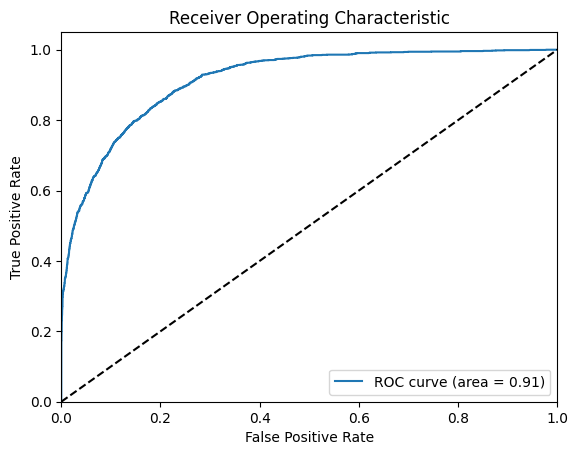

PR AUC: 0.8062529151503162


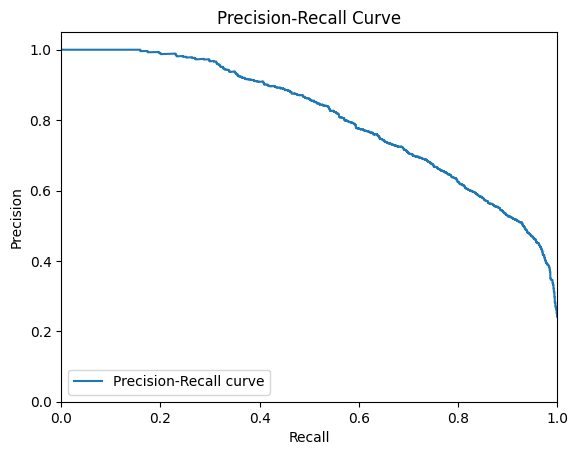

In [40]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(x_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(x_train)
stack_auto_test_pred  = stack_auto.predict(x_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(x_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [41]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
LightGBM,0.891121,0.866626,0.820317,0.766768,0.701802,0.641582,0.756446,0.698611,0.826506,0.789819,0.920219,0.817682
Hist Gradient Boosting,0.890046,0.866318,0.820335,0.770124,0.696061,0.634566,0.753106,0.695804,0.823838,0.787222,0.919422,0.816040
CatBoost,0.903070,0.866472,0.848198,0.773260,0.727954,0.630740,0.783489,0.694766,0.843302,0.786018,0.920159,0.817369
Stacking Classifier,0.881286,0.861555,0.785496,0.747955,0.697815,0.641582,0.739064,0.690697,0.818667,0.786479,0.914962,0.806253
XGBoost,0.912405,0.862323,0.860264,0.756489,0.759847,0.632015,0.806943,0.688673,0.860336,0.783720,0.918824,0.813661
Random Forest,1.000000,0.853411,1.000000,0.735429,1.000000,0.611607,1.000000,0.667827,1.000000,0.770885,0.897811,0.767988
Gradient Boosting,0.869338,0.858943,0.799582,0.778253,0.610748,0.579719,0.692523,0.664474,0.781080,0.763645,0.913097,0.804510
Extra Trees,1.000000,0.838199,1.000000,0.690600,1.000000,0.595026,1.000000,0.639260,1.000000,0.755205,0.880204,0.710198
AdaBoost,0.851012,0.847572,0.778969,0.773245,0.532770,0.519770,0.632765,0.621663,0.742395,0.735695,0.894370,0.752021
Voting Classifier,0.894425,0.853719,0.948333,0.829764,0.594164,0.494260,0.730588,0.619504,0.791945,0.731037,0.900799,0.782400


<Axes: >

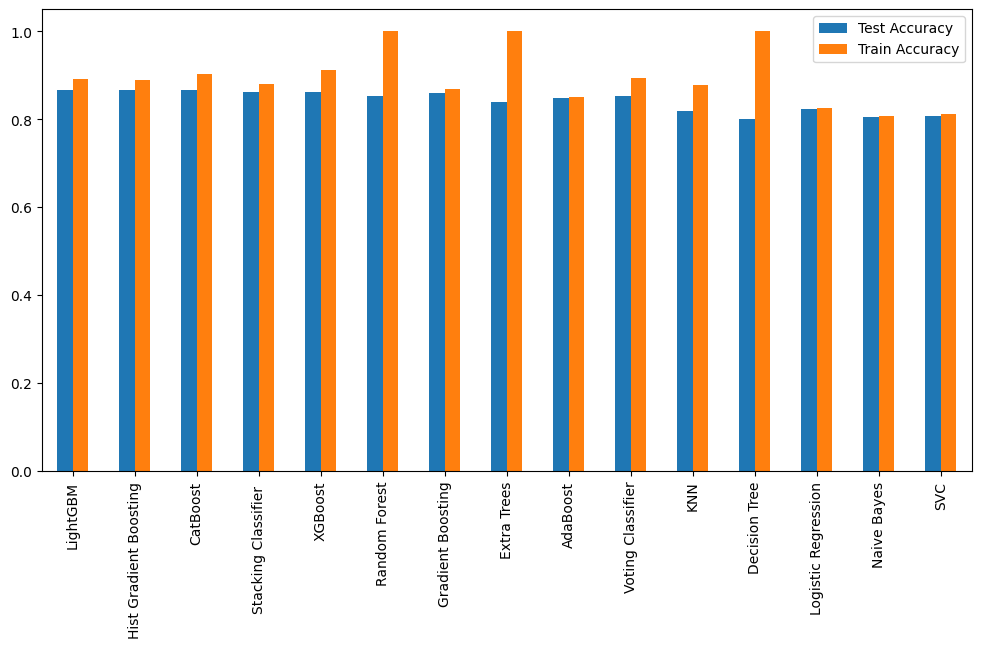

In [42]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

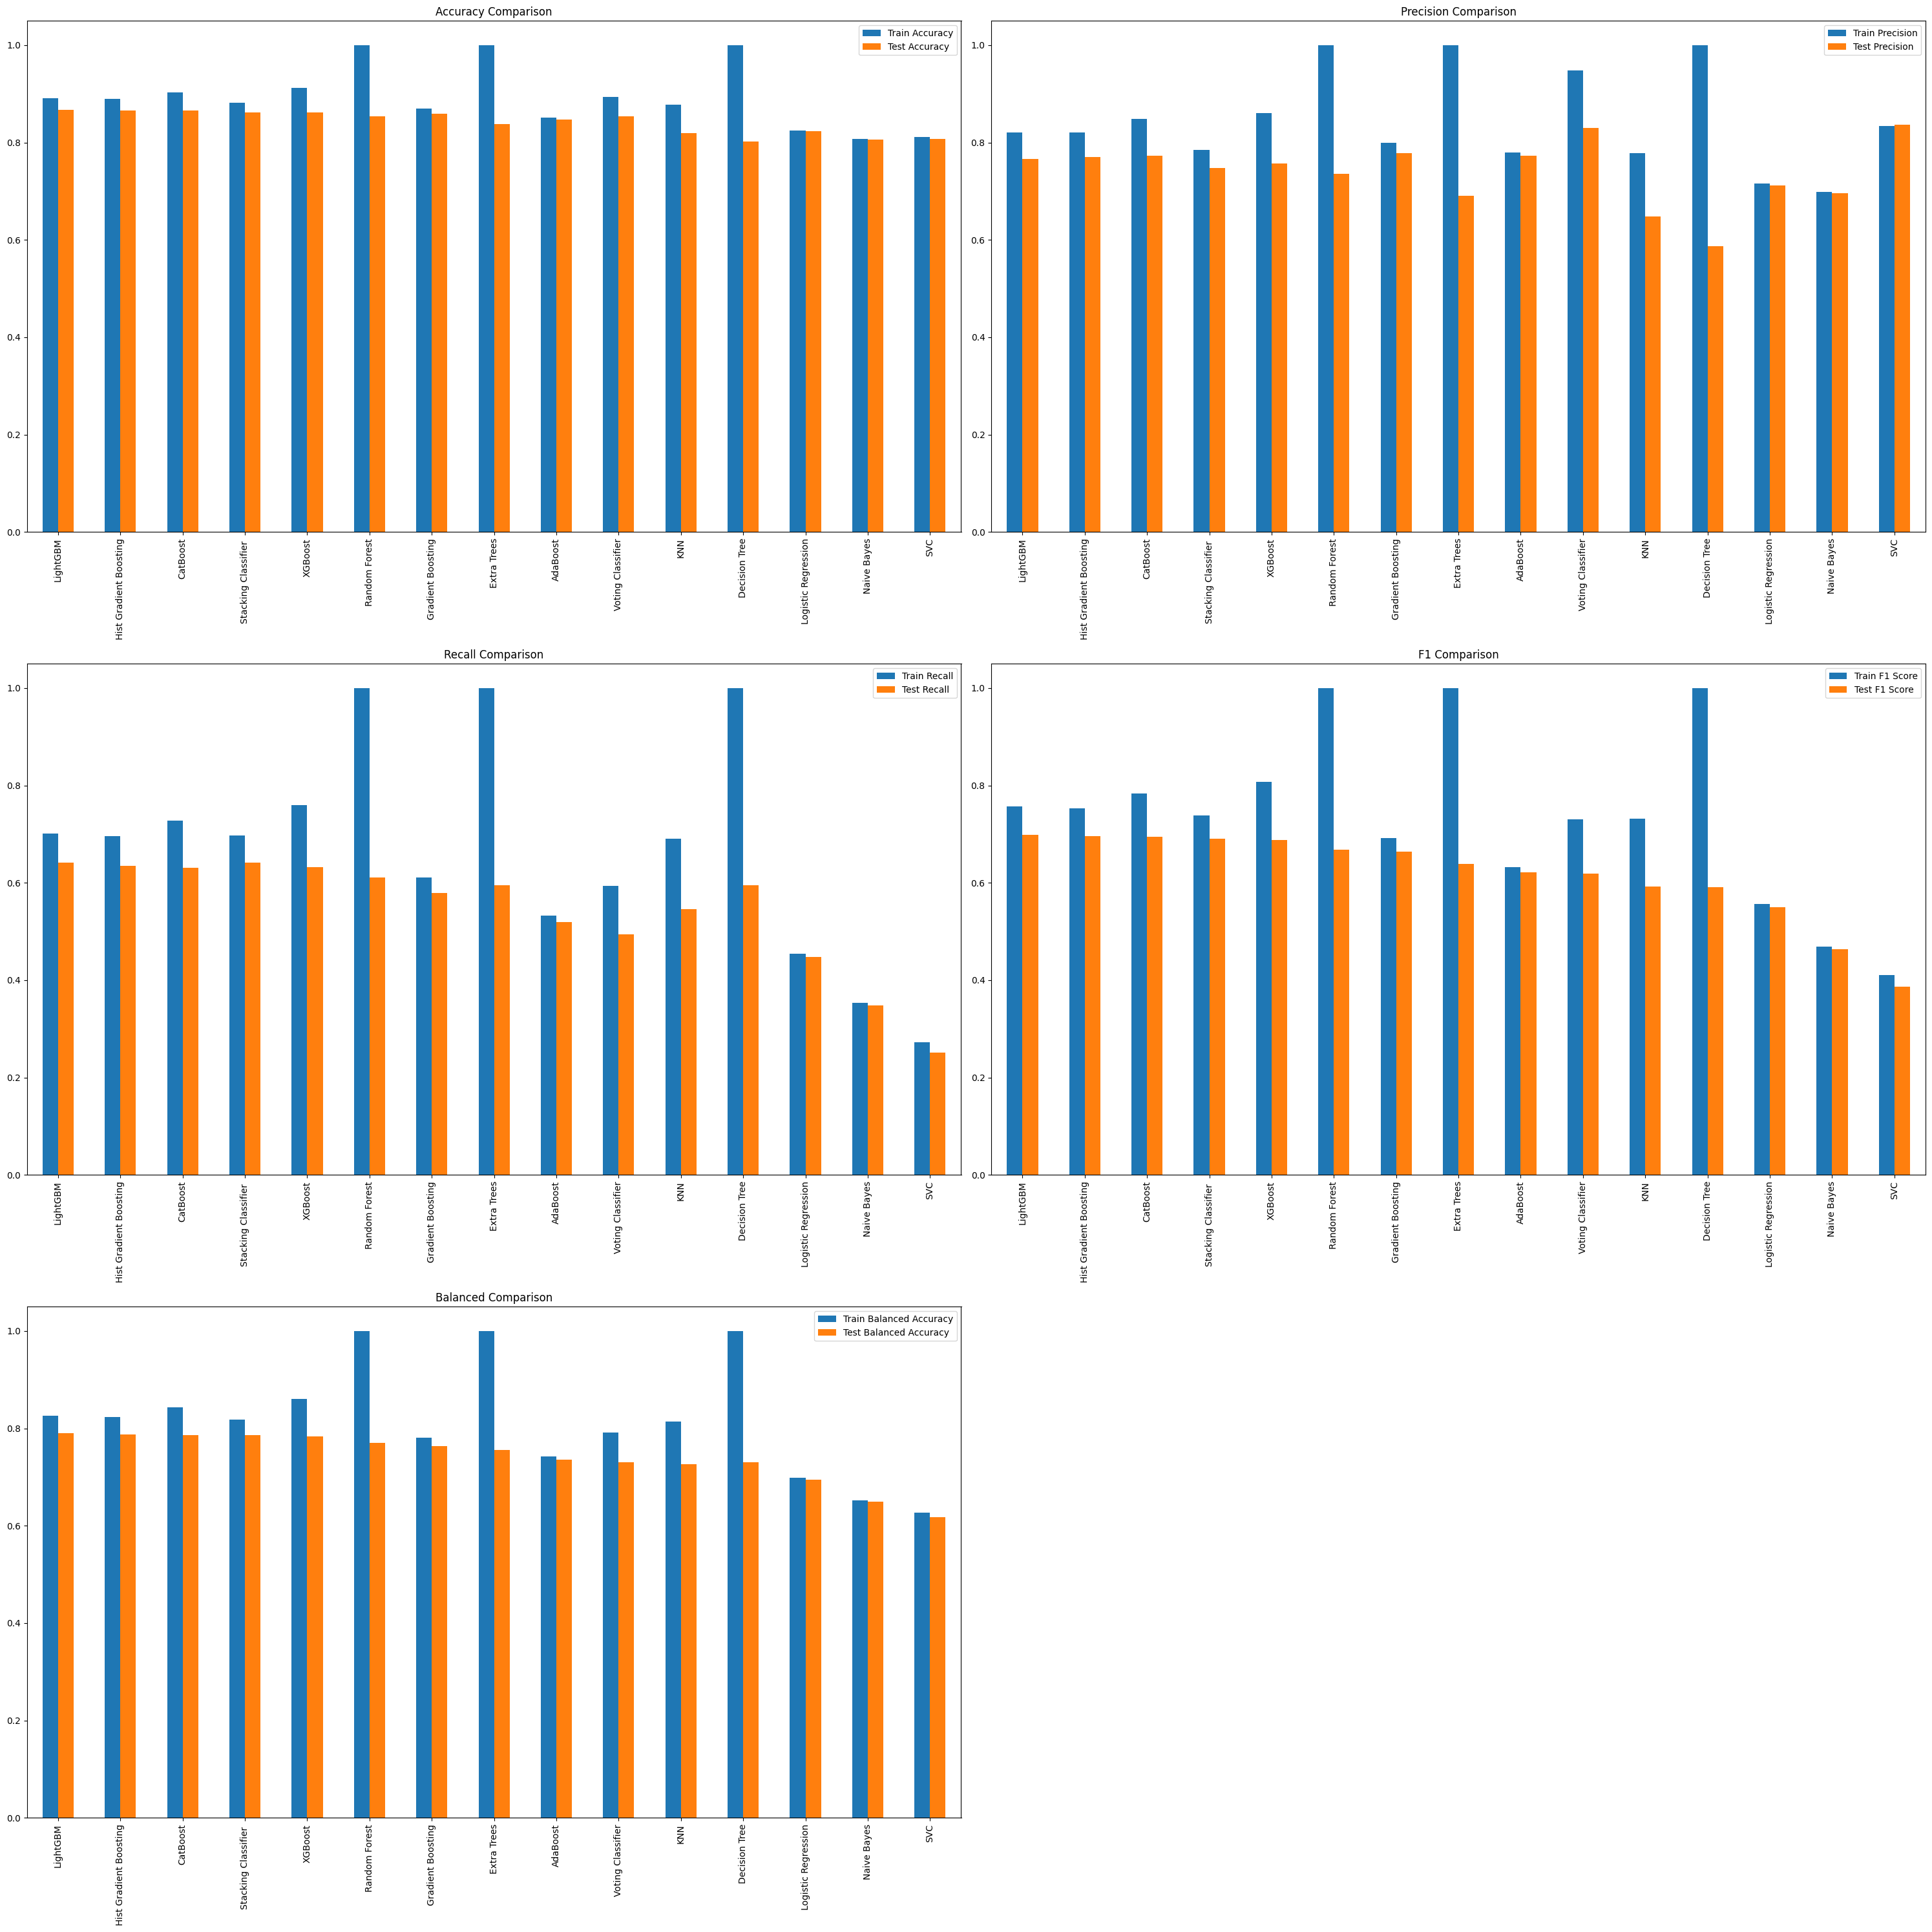

In [43]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()